# Laboratorio 4 - MLOps: predicción de demanda empresarial

**Curso:** Analítica Predictiva y Aprendizaje Automático  
**Objetivo:** llevar un modelo de predicción de demanda desde el análisis de datos hasta una solución reproducible, serializada, monitoreada y lista para una interfaz Streamlit.

En este notebook sigo el flujo indicado por el profesor y agrego interpretación empresarial. Mi criterio principal es que el modelo no sea solamente preciso: debe poder explicarse, usarse y monitorearse en una operación real.

In [1]:
import os, json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
print("Bibliotecas cargadas correctamente.")

Bibliotecas cargadas correctamente.


## 1. Carga y revisión de la base

Antes de entrenar, reviso la calidad porque una predicción puede verse muy sofisticada y aun así ser poco confiable si los datos contienen errores, duplicados o valores faltantes.

In [2]:
archivo = Path("Base_Datos_Taller_5_MLOps_Demanda.csv")
if not archivo.exists():
    try:
        from google.colab import files
        print("Cargue Base_Datos_Taller_5_MLOps_Demanda.csv")
        uploaded = files.upload()
        archivo = Path(next(iter(uploaded)))
    except Exception as exc:
        raise FileNotFoundError("No se encontró la base del laboratorio.") from exc

df = pd.read_csv(archivo)
objetivo = "Demanda_Dia_Siguiente"
print("Dimensiones originales:", df.shape)
print("Registros duplicados:", df.duplicated().sum())
print("Valores faltantes totales:", int(df.isna().sum().sum()))
display(df.isna().sum()[df.isna().sum()>0].to_frame("Cantidad"))
display(df.head())
display(df[objetivo].describe().to_frame("Demanda"))

Dimensiones originales: (1818, 29)
Registros duplicados: 18
Valores faltantes totales: 68


,Cantidad
Visitas_Web,32
Temperatura_C,36


,ID_Registro,Fecha,Tienda,Provincia,Canal_Venta,Categoria_Producto,SKU,Precio_USD,Descuento_Porc,Tipo_Promocion,Stock_Inicial,Stock_Final,Ventas_Unidades,Ingresos_USD,Visitas_Web,Conversion_Web_Porc,Inversion_Marketing_USD,Temperatura_C,Condicion_Climatica,Feriado,Dia_Semana,Mes,Demanda_Predicha_Previa,Error_Absoluto_Previa,Version_Modelo,Latencia_ms,Drift_Score,Alerta_Drift,Demanda_Dia_Siguiente
0,REG-000768,2026-03-11,CA-01,Cartago,E-commerce,Belleza,BEL-199,64.37,5,2x1,68,27,41,2507.21,29.0,4.66,20.34,19.0,Lluvioso,No,Wednesday,3,45.5,4.5,v1.3,60.9,0.076,No,38
1,REG-000600,2026-03-28,PU-01,Puntarenas,Tienda física,Tecnología,TEC-155,239.86,20,Sin promoción,49,13,36,6907.97,42.0,3.91,35.49,22.2,Soleado,No,Saturday,3,46.1,10.1,v1.3,62.4,0.073,No,21
2,REG-000163,2026-03-19,PU-01,Puntarenas,Tienda física,Hogar,HOG-174,44.60,5,Sin promoción,50,37,13,550.81,28.0,0.20,51.20,25.0,Soleado,No,Thursday,3,8.5,4.5,v1.3,63.9,0.117,No,17
3,REG-000379,2026-07-16,CA-01,Cartago,E-commerce,Hogar,HOG-125,106.37,10,Campaña digital,57,9,48,4595.18,72.0,5.74,3.77,23.9,Nublado,No,Thursday,7,57.7,9.7,v1.3,80.6,0.590,Sí,41
4,REG-001118,2026-06-22,GU-01,Guanacaste,Tienda física,Tecnología,TEC-159,139.26,0,Sin promoción,32,32,0,0.00,40.0,0.20,0.00,24.4,Nublado,No,Monday,6,8.1,8.1,v1.3,53.1,0.408,Sí,4


,Demanda
count,1818.000000
mean,33.627613
std,17.236049
min,0.000000
25%,22.000000
50%,32.000000
75%,44.000000
max,113.000000


### Interpretación personal

La base tiene suficiente volumen para hacer una prueba razonable, pero encontré dos problemas que no ignoraría en una empresa: duplicados y faltantes. En mi experiencia con operaciones de varios puntos de venta, un dato duplicado puede hacer parecer que hubo más actividad de la real, y un faltante en una variable como visitas web o temperatura puede sesgar la lectura del contexto. Por eso limpio duplicados y dejo que el pipeline impute los faltantes de forma consistente.

In [3]:
datos = df.copy().drop_duplicates().reset_index(drop=True)
datos["Fecha"] = pd.to_datetime(datos["Fecha"], errors="coerce")
datos["Anio"] = datos["Fecha"].dt.year
datos["Numero_Dia_Semana"] = datos["Fecha"].dt.dayofweek
datos["Dia_Mes"] = datos["Fecha"].dt.day

if "Descuento_Porc" in datos.columns:
    datos["Descuento_Porc"] = (datos["Descuento_Porc"].astype(str).str.replace("%","",regex=False).str.strip())
    datos["Descuento_Porc"] = pd.to_numeric(datos["Descuento_Porc"], errors="coerce")

print("Registros después de eliminar duplicados:", len(datos))
print("Demanda promedio:", round(datos[objetivo].mean(),2))

for col in ["Canal_Venta","Categoria_Producto","Tipo_Promocion","Dia_Semana","Feriado"]:
    if col in datos.columns:
        print(f"\nDemanda promedio por {col}")
        display(datos.groupby(col)[objetivo].agg(["mean","count"]).sort_values("mean",ascending=False).round(2))

Registros después de eliminar duplicados: 1800
Demanda promedio: 33.62

Demanda promedio por Canal_Venta


,mean,count
Canal_Venta,,
E-commerce,41.64,751
Online,37.15,20
Marketplace,36.83,230
Tienda física,25.06,799



Demanda promedio por Categoria_Producto


,mean,count
Categoria_Producto,,
Alimentos,49.02,293
Belleza,35.15,287
Hogar,31.98,317
Oficina,30.18,296
Deportes,28.93,293
Tecnología,27.11,314



Demanda promedio por Tipo_Promocion


,mean,count
Tipo_Promocion,,
Cupón,39.26,189
Descuento,38.18,469
Campaña digital,37.24,209
2x1,36.99,148
Sin promoción,27.93,785



Demanda promedio por Dia_Semana


,mean,count
Dia_Semana,,
Friday,39.63,272
Saturday,36.13,266
Wednesday,33.51,257
Tuesday,31.73,271
Sunday,31.54,241
Thursday,31.32,251
Monday,30.78,242



Demanda promedio por Feriado


,mean,count
Feriado,,
Sí,41.54,132
No,32.99,1668


## 2. Evitar data leakage y preparar el entrenamiento

No utilizo información que ocurre después de la predicción ni resultados de modelos anteriores. Si incorporara `Demanda_Predicha_Previa`, `Error_Absoluto_Previa`, `Drift_Score` o `Alerta_Drift` como si fueran variables normales, el modelo podría verse artificialmente bueno porque estaría recibiendo pistas que no representan una predicción limpia. Esas variables son más útiles para monitoreo.

In [4]:
columnas_excluir = [
    "ID_Registro", "Fecha", "Demanda_Dia_Siguiente",
    "Demanda_Predicha_Previa", "Error_Absoluto_Previa",
    "Version_Modelo", "Latencia_ms", "Drift_Score", "Alerta_Drift"
]
X = datos.drop(columns=columnas_excluir, errors="ignore")
y = datos[objetivo]
variables_numericas = X.select_dtypes(include=np.number).columns.tolist()
variables_categoricas = [c for c in X.columns if c not in variables_numericas]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Variables numéricas:", len(variables_numericas))
print("Variables categóricas:", len(variables_categoricas))

Entrenamiento: (1350, 23)
Prueba: (450, 23)
Variables numéricas: 14
Variables categóricas: 9


In [5]:
pipeline_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])
pipeline_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocesador = ColumnTransformer([
    ("numericas", pipeline_numerico, variables_numericas),
    ("categoricas", pipeline_categorico, variables_categoricas)
])

modelos = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Regresion_Lineal": LinearRegression(),
    "Random_Forest": RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1),
    "Gradient_Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, random_state=42),
}

resultados=[]
pipelines_entrenados={}
for nombre, modelo in modelos.items():
    pipeline = Pipeline([("preprocesamiento", preprocesador),("modelo",modelo)])
    pipeline.fit(X_train,y_train)
    pred = pipeline.predict(X_test)
    resultados.append({
        "Modelo":nombre,
        "MAE":mean_absolute_error(y_test,pred),
        "RMSE":np.sqrt(mean_squared_error(y_test,pred)),
        "R2":r2_score(y_test,pred)
    })
    pipelines_entrenados[nombre]=pipeline

resultados_df = pd.DataFrame(resultados).sort_values("MAE").reset_index(drop=True)
display(resultados_df.round(4))
mejor_nombre = resultados_df.iloc[0]["Modelo"]
mejor_modelo = pipelines_entrenados[mejor_nombre]
print("Modelo seleccionado:", mejor_nombre)

,Modelo,MAE,RMSE,R2
0,Gradient_Boosting,5.5702,7.2443,0.8124
1,Random_Forest,5.6844,7.2919,0.8100
2,Regresion_Lineal,6.9477,8.8125,0.7224
3,Baseline,13.3046,16.7294,-0.0003


Modelo seleccionado: Gradient_Boosting


### Cómo leo las métricas

- **MAE:** es la métrica que más fácil puedo llevar a una decisión operativa porque se expresa en unidades de demanda.
- **RMSE:** me ayuda a no esconder errores grandes, porque los penaliza con mayor fuerza.
- **R²:** me indica qué proporción de la variación de la demanda logra explicar el modelo.

No escogería un modelo solamente por una métrica. En este caso, Gradient Boosting queda primero de forma consistente: menor MAE, menor RMSE y mayor R².

MAE final: 5.5702
RMSE final: 7.2443
R² final: 0.8124


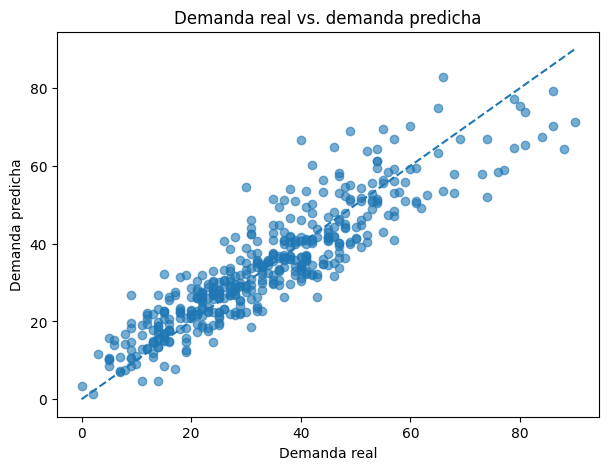

Casos con mayor error absoluto


,Demanda_Real,Demanda_Predicha,Error,Error_Absoluto
128,40,66.57,-26.57,26.57
1544,30,54.58,-24.58,24.58
482,88,64.37,23.63,23.63
538,74,51.96,22.04,22.04
570,49,69.04,-20.04,20.04
651,46,64.84,-18.84,18.84
567,90,71.23,18.77,18.77
715,42,60.29,-18.29,18.29
966,77,58.83,18.17,18.17
49,9,26.91,-17.91,17.91


In [6]:
predicciones_test = mejor_modelo.predict(X_test)
mae_final = mean_absolute_error(y_test,predicciones_test)
rmse_final = np.sqrt(mean_squared_error(y_test,predicciones_test))
r2_final = r2_score(y_test,predicciones_test)

print(f"MAE final: {mae_final:.4f}")
print(f"RMSE final: {rmse_final:.4f}")
print(f"R² final: {r2_final:.4f}")

comparacion = pd.DataFrame({"Demanda_Real":y_test.values,"Demanda_Predicha":predicciones_test}, index=y_test.index)
comparacion["Error"] = comparacion["Demanda_Real"] - comparacion["Demanda_Predicha"]
comparacion["Error_Absoluto"] = comparacion["Error"].abs()

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(comparacion["Demanda_Real"], comparacion["Demanda_Predicha"], alpha=.6)
mn = min(comparacion["Demanda_Real"].min(), comparacion["Demanda_Predicha"].min())
mx = max(comparacion["Demanda_Real"].max(), comparacion["Demanda_Predicha"].max())
ax.plot([mn,mx],[mn,mx],linestyle="--")
ax.set_title("Demanda real vs. demanda predicha")
ax.set_xlabel("Demanda real")
ax.set_ylabel("Demanda predicha")
plt.show()

print("Casos con mayor error absoluto")
display(comparacion.sort_values("Error_Absoluto",ascending=False).head(10).round(2))

### Interpretación del resultado

Un MAE cercano a 5.6 significa que el modelo se desvía, en promedio, unas 5 a 6 unidades de la demanda real. Para mí ese número no es solamente estadístico: en una operación con inventario puede representar producto de más, un faltante o una mala planificación de una promoción. El R² cercano a 0.81 indica un desempeño fuerte para este ejercicio, aunque todavía existen eventos donde el error supera 20 unidades y por eso el monitoreo sigue siendo obligatorio.

,Variable,Importancia
0,Ventas_Unidades,10.8218
1,Tipo_Promocion,0.4903
2,Dia_Semana,0.2431
3,SKU,0.0286
4,Stock_Inicial,0.0185
5,Visitas_Web,0.0173
6,Temperatura_C,0.0126
7,Dia_Mes,0.0121
8,Provincia,0.0076
9,Mes,0.0059


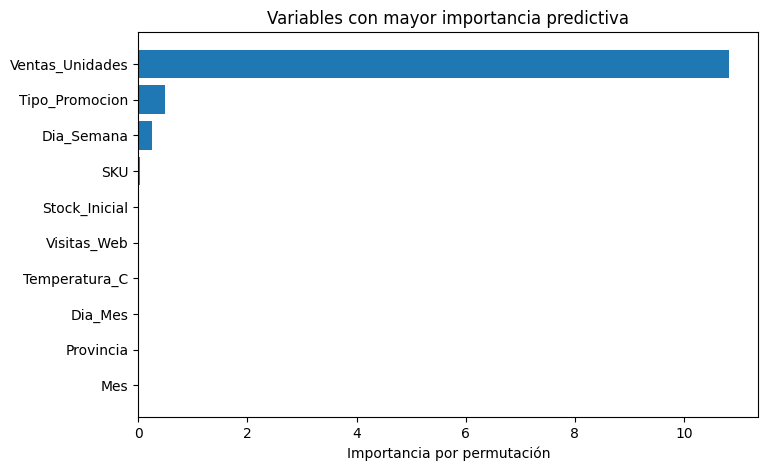

In [7]:
resultado_importancia = permutation_importance(
    mejor_modelo, X_test, y_test, n_repeats=5, random_state=42, scoring="neg_mean_absolute_error"
)
importancia = pd.DataFrame({
    "Variable":X_test.columns,
    "Importancia":resultado_importancia.importances_mean
}).sort_values("Importancia",ascending=False).reset_index(drop=True)

display(importancia.head(15).round(4))

top = importancia.head(10).sort_values("Importancia")
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(top["Variable"], top["Importancia"])
ax.set_title("Variables con mayor importancia predictiva")
ax.set_xlabel("Importancia por permutación")
plt.show()

### Lectura empresarial de las variables

`Ventas_Unidades` domina la capacidad predictiva. Después aparecen promoción, día de la semana, SKU, stock inicial, visitas web y temperatura. Esto tiene sentido desde una lógica comercial: la demanda futura suele estar conectada con el ritmo de venta reciente, disponibilidad, estímulos promocionales y comportamiento del cliente. Aun así, **importancia predictiva no significa causalidad**. Yo usaría estos resultados para orientar preguntas de negocio, no para afirmar que una variable por sí sola causa la demanda.

In [8]:
# Serialización y evidencia de producción
joblib.dump(mejor_modelo, "modelo_demanda_produccion.joblib")

metadata_modelo = {
    "nombre_modelo": mejor_nombre,
    "version": "v2.0",
    "variable_objetivo": objetivo,
    "MAE": float(mae_final),
    "RMSE": float(rmse_final),
    "R2": float(r2_final),
    "numero_registros_entrenamiento": int(len(X_train)),
    "numero_registros_prueba": int(len(X_test)),
    "umbral_advertencia_mae": float(mae_final*1.25)
}
with open("metadata_modelo.json","w",encoding="utf-8") as f:
    json.dump(metadata_modelo,f,indent=2,ensure_ascii=False)

datos_produccion = X_test.copy()
datos_produccion["Demanda_Predicha_Modelo"] = predicciones_test
datos_produccion["Demanda_Real"] = y_test.values
datos_produccion["Error_Absoluto_Modelo"] = np.abs(y_test.values-predicciones_test)

resultados_df.to_csv("Comparacion_Modelos_Demanda.csv",index=False,encoding="utf-8-sig")
importancia.to_csv("Importancia_Variables.csv",index=False,encoding="utf-8-sig")
datos_produccion.to_csv("Monitoreo_Modelo_Demanda.csv",index=False,encoding="utf-8-sig")
X_test.head(10).to_csv("datos_nuevos_ejemplo.csv",index=False,encoding="utf-8-sig")
print("Modelo y evidencias guardados correctamente.")

Modelo y evidencias guardados correctamente.


In [9]:
print("Resumen histórico de Drift_Score")
display(datos["Drift_Score"].describe().to_frame())
print("Alertas históricas")
display(datos["Alerta_Drift"].value_counts().to_frame("Cantidad"))
display((datos["Alerta_Drift"].value_counts(normalize=True)*100).round(2).to_frame("Porcentaje"))

umbral_mae = mae_final*1.25
print(f"MAE de referencia: {mae_final:.2f}")
print(f"Umbral académico de advertencia (+25%): {umbral_mae:.2f}")

Resumen histórico de Drift_Score


,Drift_Score
count,1800.000000
mean,0.207187
std,0.207063
min,0.010000
25%,0.078000
50%,0.114000
75%,0.281000
max,1.000000


Alertas históricas


,Cantidad
Alerta_Drift,
No,1431
Sí,369


,Porcentaje
Alerta_Drift,
No,79.5
Sí,20.5


MAE de referencia: 5.57
Umbral académico de advertencia (+25%): 6.96


## 3. Monitoreo, mantenimiento y criterio de reentrenamiento

Mi propuesta es no reentrenar por un solo error aislado. En una operación real revisaría el modelo mensualmente y activaría una investigación cuando el MAE supere aproximadamente 6.96 unidades. Si el deterioro se mantiene por dos periodos consecutivos, si aparecen canales o categorías nuevas, si el porcentaje de alertas de drift aumenta de forma sostenida o si cambia la relación entre promoción/ventas/demanda, entonces reentrenaría y registraría una nueva versión.

### Procedimiento mensual
1. Comparar MAE, RMSE y R² contra la referencia.
2. Revisar los mayores errores y el desempeño por canal, categoría y tienda.
3. Revisar distribución de variables y alertas de drift.
4. Confirmar si el cambio es de datos (data drift) o de relación con la demanda (concept drift).
5. Documentar la decisión: mantener, investigar o reentrenar.

### Conclusión
El principal aprendizaje de este laboratorio es que poner un modelo en producción no termina cuando la métrica es buena. El valor real aparece cuando el modelo puede usarse por una persona de negocio, se documenta, se monitorea y existe un criterio claro para saber cuándo dejó de ser confiable.